# 🇱🇰 Sri Lanka Flood Catastrophe Model
## Insurance Capital Charge under IRCSL RBC Framework
### Colombo & Western Province POC

---

**Capital Charge Formula:** `CAT Capital = OEP₂₀₀ − MAL`

| Phase | Description | Data Source |
|-------|-------------|-------------|
| 1 | Setup & Configuration | — |
| 2 | Hazard Layer (Flood Zones + Depths) | JRC GSW v1.4, Copernicus DEM |
| 3 | Exposure Layer (Buildings + Sum Insured) | Google Open Buildings v3 |
| 4 | Vulnerability (Depth-Damage Curves) | JRC Huizinga et al. 2017 |
| 5 | Loss Estimation (Monte Carlo 10,000 yrs) | Derived |
| 6 | EP Curve & Capital Charge | IRCSL RBC Rules |
| 7 | Visualisation (Maps + Charts) | Folium + Matplotlib |

## ⚙️ Phase 1: Setup & Configuration

In [1]:
%run phase1_setup.py

✅ All imports successful
✅ GEE initialized
✅ AOI defined → Colombo & Western Province
   Bounds: [79.8, 6.75, 80.25, 7.15]
✅ Constants set: 10,000 simulations, 6 return periods

🚀 Phase 1 Complete — Ready to build hazard layer


## 🌊 Phase 2: Hazard Layer

In [4]:
%run phase2_hazard.py #4-5min

✅ Phase 2 imports & constants ready
✅ DEM loaded (Copernicus GLO-30, 30m)
✅ JRC Global Surface Water v1.4 loaded
✅ Flood zone raster classified (6 return period bands)
✅ Depth rasters built for all 6 return periods

⏳ Converting flood zone raster to vector polygons...
   (reduceToVectors — this may take 60-120 seconds)
✅ Vector conversion complete: 751 flood zone polygons created

⏳ Computing zonal statistics per polygon...
   (reduceRegions — this may take 60-120 seconds)
⏳ Downloading polygon features to local memory...
✅ Zonal statistics computed: 751 polygons downloaded
✅ GeoDataFrame built: 651 valid flood zone polygons
✅ Polygon areas computed (UTM projection)

  FLOOD ZONE SUMMARY — Vector-Based (Regulatory Approach)

     RP Zone    Polygons    Area (km²)   % Total   Avg Elev (m)   Avg Occur (%)
  ---------------------------------------------------------------------------
       10-yr         114         10.09     34.6%           14.1           27.18
       25-yr         212   

## 🏢 Phase 3: Exposure Layer

In [5]:
%run phase3_exposure.py

⏳ Loading flood zone polygons...
✅ Loaded 651 flood zone polygons
   CRS: EPSG:4326
   Zones: [10, 25, 50, 100]
✅ Phase 3 imports & constants ready

✅ Open Buildings loaded
   Total buildings in AOI: 1,456,117
⏳ Fetching 5,000 building features from GEE...
✅ 5,000 buildings fetched to local DataFrame
✅ Building types classified, sum insured values assigned

⏳ Converting buildings to GeoDataFrame for spatial join...
   Buildings GeoDataFrame: 5,000 points
   Flood zones GeoDataFrame: 651 polygons
⏳ Running point-in-polygon spatial join...
✅ Point-in-polygon spatial join complete
   Every building now has its EXACT flood zone from polygon boundary

  SPATIAL JOIN QUALITY REPORT

  Total buildings                 :    5,000
  Buildings INSIDE flood zones    :       37  (0.7%)
  Buildings OUTSIDE flood zones   :    4,963  (99.3%)

  Zone-by-zone breakdown:
        Zone     Buildings    % Portfolio    Avg Depth@RP (m)
  ----------------------------------------------------------
       10-yr

## 📉 Phase 4: Vulnerability (JRC Huizinga Curves)

✅ buildings_df loaded: 5,000 buildings
✅ Phase 4 imports & constants ready
✅ JRC Huizinga depth-damage curves loaded (Asia region)
   Curve types: ['residential', 'commercial', 'industrial', 'contents_residential', 'contents_commercial']

Computing mean damage ratios for all buildings × return periods...
✅ Damage ratios computed for all return periods


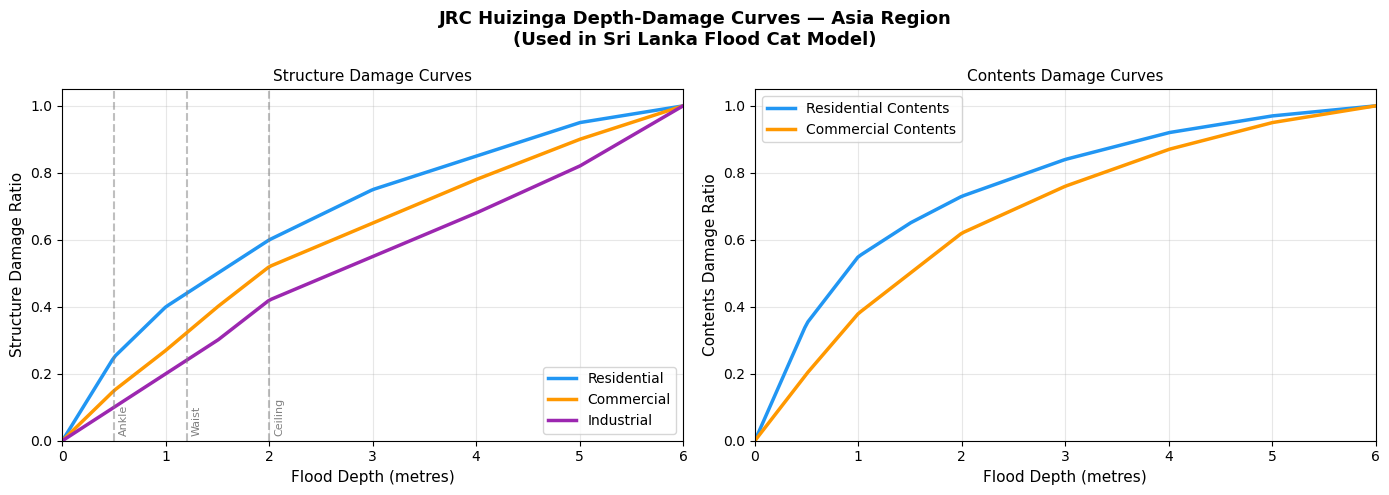

✅ Figure saved: fig1_depth_damage_curves.png

📋 Damage Ratio Preview (sample depths):
Depth (m)   residential_small     residential_standard  commercial_mixed      commercial_large      
----------------------------------------------------------------------------------------------------
0.3         0.15                  0.15                  0.09                  0.06                  
0.5         0.25                  0.25                  0.15                  0.10                  
1.0         0.40                  0.40                  0.27                  0.20                  
1.5         0.50                  0.50                  0.40                  0.30                  
2.0         0.60                  0.60                  0.52                  0.42                  
3.0         0.75                  0.75                  0.65                  0.55                  

🚀 Phase 4 Complete — Vulnerability functions ready
✅ buildings_df (with damage ratios) saved → buildings_

In [1]:
%run phase4_vulnerability.py

## 🎲 Phase 5: Monte Carlo Loss Estimation

In [2]:
%run phase5_loss_estimation.py

✅ calculate_damage_ratio re-defined in Phase 5
✅ buildings_df loaded: 5,000 buildings with damage ratios
✅ Phase 5 imports & constants ready
📋 Stochastic Event Catalog:
                         name  return_period  annual_rate  spatial_coverage
Minor Flood - Kelani R. local             10        0.100              0.15
 Minor Flood - Kelani R. wide             10        0.100              0.25
     Moderate Flood - Western             25        0.040              0.20
     Moderate Flood - Coastal             25        0.040              0.18
   Major Flood - Kelani Basin             50        0.020              0.30
  Major Flood - Metro Colombo             50        0.020              0.22
    Severe Flood - Basin wide            100        0.010              0.40
 Severe Flood - Coastal surge            100        0.010              0.28
         Extreme - 1-in-200yr            200        0.005              0.55
 Extreme - 1-in-200yr coastal            200        0.005              

## 📊 Phase 6: EP Curve & IRCSL Capital Charge

In [3]:
%run phase6_capital_charge.py

✅ Loaded: 5,000 buildings, 10,000 simulated years
✅ Phase 6 imports & constants ready
✅ EP Curve constructed

  CATASTROPHE CAPITAL CHARGE — IRCSL RBC FRAMEWORK
  Colombo & Western Province Flood Model

  ── Loss at Key Return Periods ─────────────────────────
  Mean Annual Loss (MAL)      : LKR    0.007 Billion
  1-in-10yr  (OEP 90th pct)  : LKR    0.029 Billion
  1-in-50yr  (OEP 98th pct)  : LKR    0.056 Billion
  1-in-100yr (OEP 99th pct)  : LKR    0.069 Billion
  1-in-200yr (OEP 99.5th)    : LKR    0.080 Billion  ←  Regulatory Threshold
  1-in-500yr (OEP 99.8th)    : LKR    0.102 Billion

  ── IRCSL Capital Charge Calculation ────────────────────
  Formula: CAT Capital = OEP_200yr − MAL
  CAT Capital Charge          : LKR    0.072 Billion
  CAT Capital (USD)           : USD      0.2 Million
  As % of Total Insured Value :    0.037%

  ── Portfolio Context ────────────────────────────────────
  Total Insured Value (TIV)   : LKR   195.53 Billion
  Flood-exposed TIV           : LKR   

## 🗺️ Phase 7: Visualisation

✅ Phase 7 imports & constants ready
✅ All data loaded: 5,000 buildings, 10,000 sim years
   MAL=LKR 0.440B | OEP200=LKR 4.252B | Capital=LKR 3.812B
Building interactive flood hazard + exposure map...
✅ Interactive map saved: flood_hazard_exposure_map.html


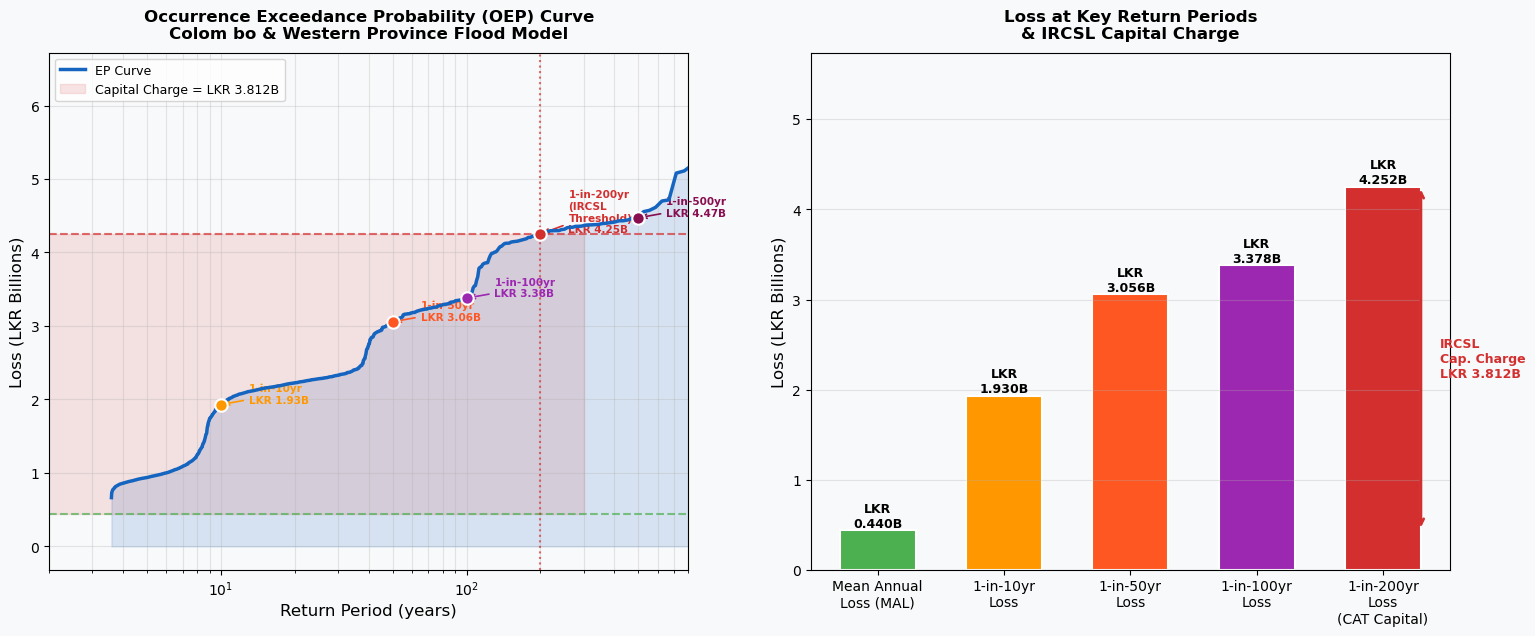

✅ Figure saved: fig2_ep_curve.png


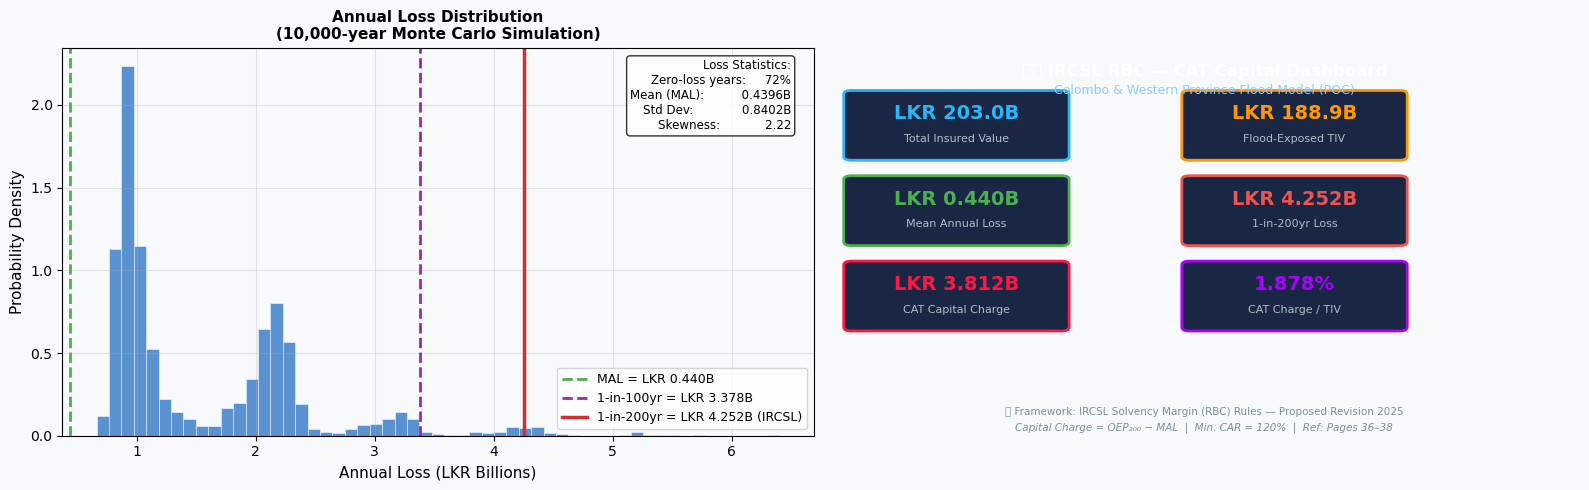

✅ Figure saved: fig3_loss_distribution_dashboard.png

  🎉 ALL 7 PHASES COMPLETE!

  📁 Output Files:
     • flood_hazard_exposure_map.html  → Open in browser
     • fig1_depth_damage_curves.png    → Vulnerability curves
     • fig2_ep_curve.png               → EP curve + capital
     • fig3_loss_distribution_dashboard.png → Full dashboard
     • ep_curve.csv                    → Raw EP curve data

  🔑 Key Numbers for IRCSL Submission:
     MAL                : LKR 0.440 Billion
     1-in-200yr Loss    : LKR 4.252 Billion
     CAT Capital Charge : LKR 3.812 Billion
     As % of TIV        : 1.878%

  📚 Data Sources:
     • JRC Global Surface Water v1.4 (GEE)
     • Copernicus GLO-30 DEM (GEE)
     • Google Open Buildings v3 (GEE)
     • JRC Huizinga et al. 2017 (depth-damage curves)
     • IRCSL RBC Rules 2025 (capital framework)


In [12]:
%run phase7_visualization.py

---
## 📋 IRCSL Submission Notes

As per the IRCSL RBC consultation document, for an **internally developed catastrophe model** to be accepted:

1. ✅ **Model must be approved by the Appointed Actuary** of the insurer
2. ✅ **Submitted to IRCSL for approval** before use in solvency returns
3. ✅ **Capital = 99.5th percentile − Mean Annual Loss** (i.e., OEP₂₀₀ − MAL)
4. ✅ **Alternatively**: use flat factor of 0.05% × Sum Insured for flood (simpler but less accurate)

This POC demonstrates the internal model approach which, if validated,
allows a more **risk-sensitive** capital requirement than the flat factor.